# Dans quelle mesure les conditions météorologiques expliquent-elles la consommation et la production d'électricité en France ?

Avec près de 28 % d'énergies renouvelables dans sa production d'électricité en 2024\* (hydraulique, éolien, solaire), la France est particulièrement exposée aux aléas météorologiques, du côté de l'offre autant que de la demande : la pluie alimente les barrages, le vent fait tourner les éoliennes, le soleil alimente le photovoltaïque, et les besoins en chauffage dépendent fortement de la température. A cette aune, nous avons choisi d'étudier ce phénomène à travers ce projet python.

\* Bilan électrique annuel 2024, RTE.

## Notre démarche

Si cette problématique est complexe et dépasse largement le cadre de ce projet, nous avons choisi d'y répondre par 5 hypothèses simples, que nous tenterons de confirmer ou d'infirmer à l'aide d'une analyse de données.

Voici ces 5 hypothèses :

**Consommation** : 
Nous nous attendons, à l'échelle annuelle, à une hausse de la consommation d'électricité lorsque les températures descendent en dessous d'un certain seuil (15 degrés), en raison du chauffage, mais également lorsqu'elles dépassent un autre seuil (27 degrés), à cause de la climatisation. 

**Production**  :
Nous chercherons à vérifier quatre hypothèses :

1. La production éolienne augmente avec la vitesse du vent. 
2. La production solaire suit l'ensoleillement : nulle la nuit, maximale vers midi et en été. 
3. La production hydraulique dépend des précipitations, avec un décalage dans le temps. 
4. La production nucléaire est peu sensible à la météo, sauf lors des canicules (limitations dues à la température des cours d'eau).

## Limitations et choix de modélisation

- Nos données sont limitées à la période 2021-2025, afin de travailler sur une période récente tout en excluant les confinements (2020), qui auraient ajouté du bruit aux données.
- Nous approchons la météo de chaque région par celle de sa plus grande ville (l'Île-de-France est représentée par Paris...). Cette hypothèse est forte, notamment pour l'éolien, dont la ressource peut varier fortement à l'échelle d'une région.
    - Paris : Île-de-France
    - Lyon : Auvergne-Rhône-Alpes
    - Toulouse : Occitanie
    - Bordeaux : Nouvelle-Aquitaine
    - Lille : Hauts-de-France
    - Strasbourg : Grand Est
    - Marseille : Provence-Alpes-Côte d'Azur
    - Nantes : Pays de la Loire
    - Rennes : Bretagne
    - Rouen : Normandie
    - Dijon : Bourgogne-Franche-Comté
    - Orléans : Centre-Val de Loire

## Sources et API utilisées

Deux API complémentaires ont été mobilisées :

- **éCO2mix (ODRE - Open Data Réseau Énergies)** : production et consommation d'électricité en France.
- **Open-Meteo** : données météorologiques détaillées (température, précipitations, vitesse du vent...) sur l'ensemble du territoire.

## Fichiers et organisation

- `data/` : jeux de données utilisés et leur mode de téléchargement .
- `Rendu_final.ipynb` : notebook retraçant l'ensemble du déroulé du projet, de la collecte des données à l'analyse des hypothèses.
- `src` : Fichier dans lequel se trouvent les fichier py dans lesquel toutes les fonctions utilisées dans le rendu final sont détaillées. 

Présentation des données et traitement

API Open Météo : 
On va commencer par une présentation rapide des données pur (meteo_pur) telles qu'on les a téléchargéees puis on détailleras le traitement qu'on y a effectué et enfin on explorera plus en détails ces données à l'aide de statistiques descriptives.

In [21]:
from src.meteo import charger_meteo
from IPython.display import display #Pour afficher des beaux tableaux


#On appelle meteo_pur la data sans aucun traitement telle qu'on  l'a téléchargée de Open Meteo
meteo_pur= charger_meteo("data/raw/openmeteo") 

#Voila un aperçu des données
print(display(meteo_pur.head()), display(meteo_pur.describe()))

#On observe bien que nos données couvre du premier janvier 2021 au 31 décembre 2025
print( "Les données couvrent de "+ str(meteo_pur["time"].min()) +" à " +str( meteo_pur["time"].max()))

#On observe bien que les 12 régions de la France métropolitaine (13 - la Corse) sont bien présentes (1 ville par région)
print("On observe bien au total "+str(meteo_pur["ville"].nunique() )+" régions")



,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville
0,2021-01-01 00:00:00+00:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux
1,2021-01-01 01:00:00+00:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux
2,2021-01-01 02:00:00+00:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux
3,2021-01-01 03:00:00+00:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux
4,2021-01-01 04:00:00+00:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux


,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation
count,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000
mean,12.986467,151.895489,61.493029,12.207613,20.616850,0.099247
std,7.283659,227.364982,41.271378,6.945876,10.762091,0.457567
min,-11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.900000,0.000000,15.000000,7.100000,12.800000,0.000000
50%,12.700000,7.000000,83.000000,10.900000,19.700000,0.000000
75%,18.000000,249.000000,100.000000,16.000000,26.800000,0.000000
max,41.700000,958.000000,100.000000,69.900000,102.400000,24.400000


None None
Les données couvrent de 2021-01-01 00:00:00+00:00 à 2025-12-31 23:00:00+00:00
On observe bien au total 12 régions


Tout d'abords, on a bien 525888 lignes, nos données couvrent bien la période attendue (de janvie 2021 à décembre 2025) et les douze régions (dans toute la suite ces régions seront représentées par leur plus grande ville) à savoir la france métropolitaine sans la Corse.


Première remarque sur les données, on peut observer que la température moyenne est égale à environ 13 degrés, ce qui est considéré comme froid selon notre convention. 
C'est l'effet de la nuit sur la température moyenne (certains jours chaud d'été ont une température inférieur à 15°C la nuit mais ne sont pas froids pour autant).
On prendra ce problème en compte dans notre traitement des données en considérant les jours froids comme ayant une température moyenne sous 15°C et les jours chaud comme ayant une température maximale au dessus de 27°C.

On observe aussi que les valeurs ne sont pas aberrantes (une température maximal de 41.7°C, minimale de -11°C). Par curiosité, on voudrait savoir dans quelle ville on atteint tel ou tel extrema métérologique. 

Par exemple si on veut s'intéresser aux températures minimales dans les douzes villes et à la vitesse de vent maximale à 100m à Paris


In [15]:
from src.meteo import extremum_meteo
print(display(extremum_meteo(meteo_pur, "temperature_2m", mode="min")),display(extremum_meteo(meteo_pur, "wind_speed_100m", mode="max", ville="paris")))

,ville,time,valeur
0,bordeaux,2022-12-17 07:00:00+01:00,-4.8
1,dijon,2021-02-13 08:00:00+01:00,-8.6
2,lille,2021-02-09 07:00:00+01:00,-7.6
3,lyon,2021-02-14 08:00:00+01:00,-7.0
4,marseille,2023-12-03 08:00:00+01:00,-0.5
5,nantes,2024-01-20 09:00:00+01:00,-3.9
6,orleans,2021-02-13 08:00:00+01:00,-6.4
7,paris,2024-01-20 01:00:00+01:00,-6.1
8,rennes,2024-01-19 05:00:00+01:00,-5.4
9,rouen,2021-02-10 08:00:00+01:00,-6.3


,ville,time,valeur
0,paris,2021-10-21 05:00:00+02:00,76.7


None None


A noter que notre fonction ne garder qu'une date à chaque fois, donc il  y a potentiellement pleins de dates ex-aequo (par exemple sur le minimum de la vitesse du vent, il y en aura beaucoup à 0)

In [16]:
from src.meteo import preparer_meteo
#Les données sont globalement déjà propres
print("pour chaque variable, on vérifie bien qu'on a toutes les observations", meteo_pur.isna().sum(), "puis combien de doublon il y a",meteo_pur.duplicated(["ville", "time"]).sum())
#Les noms de colonnes sont également assez explicites donc on a pas vraiment trouvé d'intérêt à les renommer.



pour chaque variable, on vérifie bien qu'on a toutes les observations time                   0
temperature_2m         0
shortwave_radiation    0
cloud_cover            0
wind_speed_10m         0
wind_speed_100m        0
precipitation          0
ville                  0
dtype: int64 puis combien de doublon il y a 0


Les données telles qu'elles sont importéees sont déjà assez propres ( pas de doublon ni de valeurs manquantes).
On va cependant enrichir la base de données de quelques nouvelles colonnes :
- Deux colonnes booléennes savoir si la température est sous 15°C ou au dessus de 17 (sous_15, sup_27)
- Deux colonnes avec la valeur indiquant de combien la température dépasse ou est dépassée par les seuils respectifs (deg_sous_15, deg_sup_27) 
- La température maximale (tmax_jour), moyenne (tmoy_jour) de chaque jour, si le jour est chaud (tmax>27) ou froid (tmoy<15)
- La vitesse maximal et moyenne du vent à 100 mètres.

In [22]:
meteo = preparer_meteo(meteo_pur) 
meteo.head()

,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville,jour,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,2021-01-01 01:00:00+01:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux,2021-01-01,True,False,10.6,0.0,6.1,3.752174,False,True,18.308696,28.0
1,2021-01-01 02:00:00+01:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux,2021-01-01,True,False,11.7,0.0,6.1,3.752174,False,True,18.308696,28.0
2,2021-01-01 03:00:00+01:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux,2021-01-01,True,False,12.9,0.0,6.1,3.752174,False,True,18.308696,28.0
3,2021-01-01 04:00:00+01:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux,2021-01-01,True,False,13.1,0.0,6.1,3.752174,False,True,18.308696,28.0
4,2021-01-01 05:00:00+01:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux,2021-01-01,True,False,13.2,0.0,6.1,3.752174,False,True,18.308696,28.0


Rapide exploration des données d'Open Meteo

Nous allons effectuer quelques graphiques utiles pour explorer nos données et pour plus tard considérer nos hypothèses.

Tout d'abords pour vérifier la corrélation entre production d'énérgie hydraulique et précipatation, il sera utile d'avoir un graphe des précipitations. On regroupe les données par mois et on affiche le graphique pour Bordeaux.

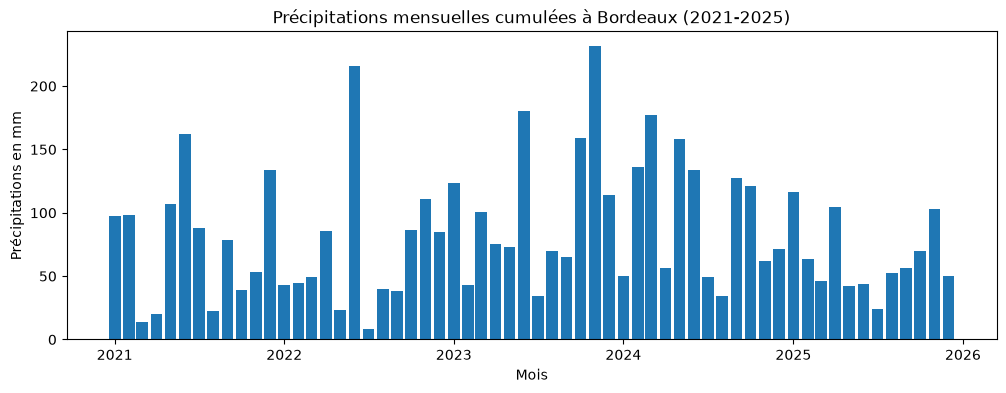

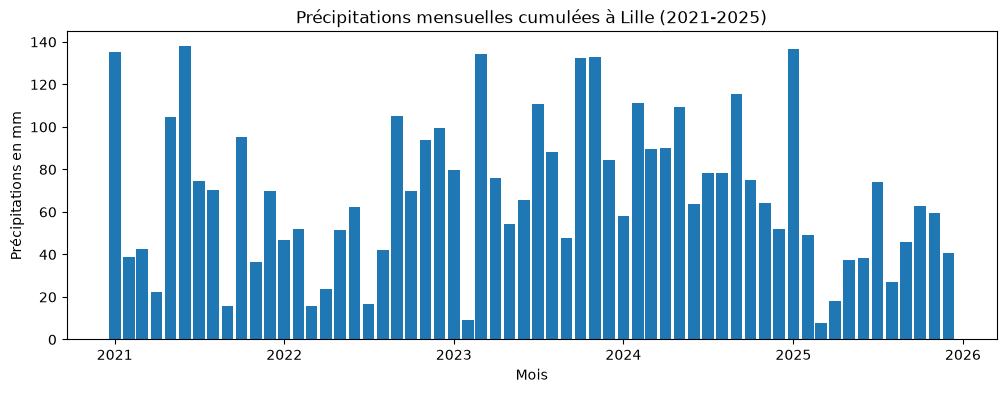

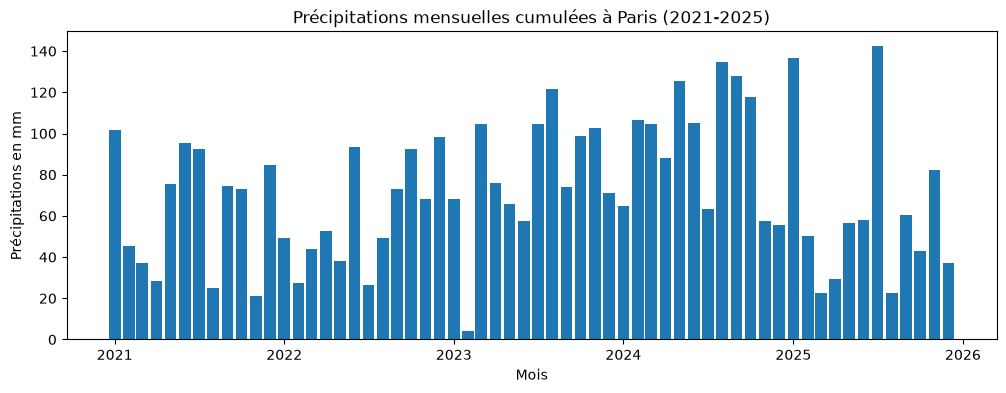

In [19]:
import matplotlib.pyplot as plt
from src.meteo import tracer_cumul_mensuel_precipitation
ville = "bordeaux" #en tant que bordelais je peux attester que Bordeaux devrait être riche en données sur ce point !
tracer_cumul_mensuel_precipitation(meteo, ville)
tracer_cumul_mensuel_precipitation(meteo, "lille")
tracer_cumul_mensuel_precipitation(meteo, "paris")

On peut observer que les précipitations sont irrégulières sans vrai cycle apparant mais qu'on retrouve certains éléments en communs entre les villes, ce qui est attendu (chute début 2023, pic à la fin de l'année qui s'abaisse jusqu'à janvier 2024 par exemple)

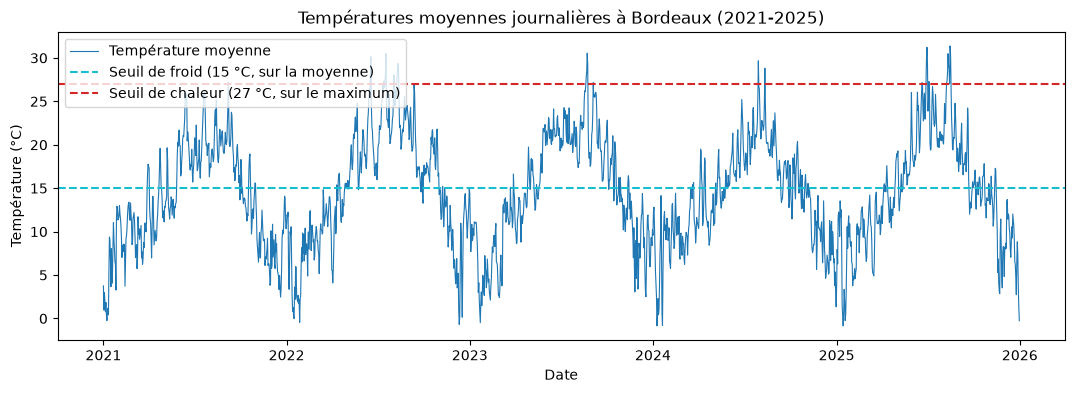

In [ ]:
import src.meteo
from src.meteo import tracer_temperature_moyenne_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_moyenne_jour(meteo,ville)

Tout d'abords il est rassurant de noter que l'on aperçoit les saisons sur ce graphe !

Ensuite pour ce qui est de notre analyse,on observe que très peu de jours sont au dessus du seuil de chaleur (27 degré). C'est "l'effet nuit" qu'on a déjà mentionné. On va donc considérer la température maximal journalière pour ce seuil chaud.

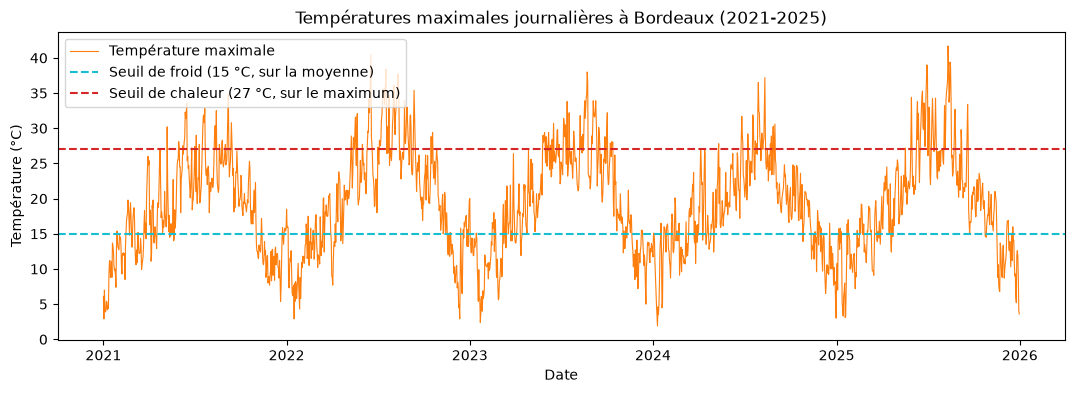

In [5]:
from src.meteo import tracer_temperature_max_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_max_jour(meteo,ville)


Un nombre bien plus important de jours sont alors considérés comme chaud. On voudrait maintenant savoir exactement combien de jours sont considérés comme chaud ou froid.

In [6]:
# Un seul enregistrement par ville et par jour
jours = meteo.drop_duplicates(["ville", "jour"])

# Nombre de jours froids par ville (2021-2025)
jours_froids = jours.groupby("ville")["jour_froid"].sum().sort_values(ascending=False)
print("Jours froids par ville :")
print(jours_froids)

# Nombre de jours chauds par ville (2021-2025)
jours_chauds = jours.groupby("ville")["jour_chaud"].sum().sort_values(ascending=False)
print("\nJours chauds par ville :")
print(jours_chauds)

Jours froids par ville :
ville
rouen         1233
lille         1220
dijon         1192
rennes        1168
paris         1156
orleans       1152
strasbourg    1145
nantes        1090
lyon          1084
bordeaux       994
toulouse       986
marseille      857
Name: jour_froid, dtype: int64

Jours chauds par ville :
ville
toulouse      349
marseille     310
lyon          293
bordeaux      265
strasbourg    198
dijon         171
paris         161
orleans       158
nantes        147
rennes        122
rouen          85
lille          82
Name: jour_chaud, dtype: int64


On retrouve le fait qu'on est beaucoup plus de jours froids que de jours chaud mais également que les villes au Nord sont beaucoup plus froide que les villes au Sud et inversement (rien de très surprenant).

On va faire le même travail pour la vitesse du vent à 100m (les éoliennes faisant plus de 100m c'est la valeur pertinente)

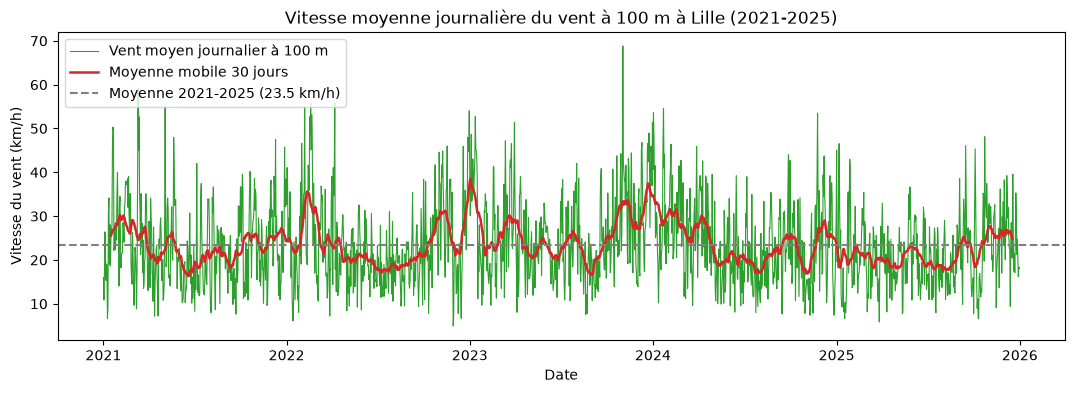

In [ ]:
import matplotlib.pyplot as plt
from src.meteo import tracer_vent_moyen_jour

ville = "lille"
tracer_vent_moyen_jour(meteo, ville)

Ces valeurs varient énormèment du jour au lendemain donc pour rendre le graphique plus lisible on a rajouté une moyenne mobible sur un mois.

API : ECO2Mix

In [23]:
import pandas as pd

#On appelle elec_pur les données éCO2mix telles qu'on les a téléchargées depuis l'API ODRÉ
from src.electricite import charger_eco2mix

elec_pur = charger_eco2mix()

#Aperçu des données
display(elec_pur.head())

#Vérification de la période couverte et du nombre de régions
print("Les données couvrent de " + str(elec_pur["date_heure"].min()) + " à " + str(elec_pur["date_heure"].max()))
print("On observe au total " + str(elec_pur["code_insee_region"].nunique()) + " régions")


,code_insee_region,libelle_region,date_heure,consommation,nucleaire,eolien,solaire,hydraulique
0,44,Grand Est,2025-12-31T23:30:00+00:00,5870.0,8963.0,45,0.0,524.0
1,11,Île-de-France,2025-12-31T23:30:00+00:00,10410.0,0.0,0,0.0,5.0
2,52,Pays de la Loire,2025-12-31T23:30:00+00:00,4569.0,0.0,934,0.0,3.0
3,24,Centre-Val de Loire,2025-12-31T23:30:00+00:00,3139.0,10323.0,148,0.0,3.0
4,76,Occitanie,2025-12-31T23:30:00+00:00,6387.0,1247.0,55,0.0,1377.0


Les données couvrent de 2021-01-01T00:00:00+00:00 à 2025-12-31T23:30:00+00:00
On observe au total 12 régions


In [24]:
from src.electricite import preparer_eco2mix

#On passe de la demi-heure à l'heure (moyenne des deux demi-heures, car ce sont des puissances en MW)
#et on associe à chaque région son chef-lieu, pour pouvoir fusionner avec la météo
elec_horaire = preparer_eco2mix(elec_pur)

display(elec_horaire.head())
print("Nombre de lignes : " + str(len(elec_horaire)))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville
0,11,2021-01-01 00:00:00+00:00,9495.0,0.0,1.0,0.0,3.0,paris
1,11,2021-01-01 01:00:00+00:00,9061.0,0.0,1.5,0.0,3.0,paris
2,11,2021-01-01 02:00:00+00:00,8690.0,0.0,0.0,0.0,3.0,paris
3,11,2021-01-01 03:00:00+00:00,8429.0,0.0,0.0,0.0,3.0,paris
4,11,2021-01-01 04:00:00+00:00,8446.5,0.0,0.5,0.0,3.0,paris


Nombre de lignes : 525828


Après passage à l'heure, on obtient 525 828 lignes au lieu des 525 888 attendues (12 villes × 1 826 jours × 24 heures). Il manque une heure par an et par région : celle du passage à l'heure d'hiver en octobre (00h-01h UTC), absente des données RTE. Ces 60 heures, soit 0,01 % des données, seront écartées lors de la jointure avec la météo.


In [10]:
from src.electricite import COLONNES_ELEC

#Statistiques descriptives des données d'électricité horaires (en MW)
display(elec_horaire[COLONNES_ELEC].describe().round(0))

#On vérifie qu'il n'y a ni valeur manquante ni doublon (une seule ligne par ville et par heure)
print("Valeurs manquantes : " + str(elec_horaire.isna().sum().sum()))
print("Doublons ville-heure : " + str(elec_horaire.duplicated(["ville", "time"]).sum()))


,consommation,nucleaire,eolien,solaire,hydraulique
count,525828.0,525828.0,525828.0,525828.0,525828.0
mean,4256.0,3222.0,424.0,212.0,581.0
std,2020.0,3545.0,663.0,461.0,997.0
min,430.0,0.0,0.0,0.0,0.0
25%,2632.0,0.0,51.0,0.0,6.0
50%,3970.0,2358.0,187.0,4.0,56.0
75%,5390.0,6188.0,518.0,186.0,844.0
max,14688.0,13686.0,5870.0,4849.0,8277.0


Valeurs manquantes : 0
Doublons ville-heure : 0


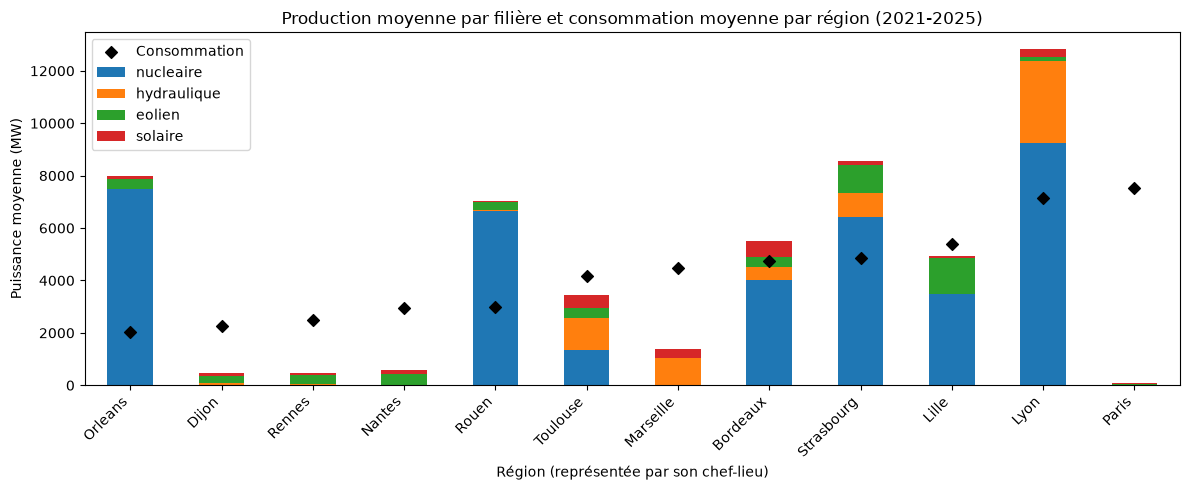

,consommation,nucleaire,eolien,solaire,hydraulique
ville,,,,,
orleans,2017.0,7492.0,363.0,130.0,14.0
dijon,2277.0,0.0,251.0,107.0,102.0
rennes,2485.0,0.0,327.0,66.0,67.0
nantes,2956.0,0.0,414.0,154.0,3.0
rouen,2997.0,6670.0,308.0,40.0,13.0
toulouse,4183.0,1360.0,391.0,510.0,1190.0
marseille,4488.0,0.0,24.0,336.0,1022.0
bordeaux,4754.0,4009.0,381.0,623.0,498.0
strasbourg,4868.0,6412.0,1041.0,182.0,938.0


In [11]:
from src.electricite import tracer_moyennes_par_region

moyennes_region = tracer_moyennes_par_region(elec_horaire)
display(moyennes_region)


**Statistiques descriptives des données d'électricité**

Les données horaires ne comportent ni valeur manquante ni doublon : chaque ville a une seule ligne par heure.

Le tableau `describe()` montre que la consommation horaire moyenne d'une région est de 4 256 MW, avec de fortes variations
(de 430 à 14 688 MW selon la région, l'heure et la saison). Pour le nucléaire, la médiane (2 358 MW) est nettement inférieure
à la moyenne (3 222 MW) et le premier quartile vaut 0 : cinq régions n'ont aucune centrale (Île-de-France, Bourgogne-Franche-Comté,
Bretagne, Pays de la Loire, PACA). Pour le solaire, la médiane n'est que de 4 MW, car la production est nulle la nuit, soit près
de la moitié des heures.

Le graphique met en évidence des profils régionaux très différents :
- l'**Île-de-France** (Paris) est la région qui consomme le plus (7 514 MW en moyenne) mais ne produit presque rien : elle dépend
  entièrement des autres régions ;
- le **Centre-Val de Loire** (Orléans) et la **Normandie** (Rouen) produisent bien plus qu'elles ne consomment, grâce au nucléaire
  (près de 4 fois sa consommation pour le Centre-Val de Loire) ;
- l'**Auvergne-Rhône-Alpes** (Lyon) est la première région productrice, avec beaucoup de nucléaire et d'hydraulique (Alpes, Rhône) ;
- l'**éolien** est surtout présent dans les Hauts-de-France (Lille) et le Grand Est (Strasbourg), l'**hydraulique** dans les régions
  de montagne (Lyon, Toulouse, Marseille), le **solaire** dans le Sud-Ouest (Bordeaux, Toulouse).

Ces différences justifient de mener l'analyse région par région, et de limiter l'étude du nucléaire aux sept régions qui en produisent.

*Limite :* seules quatre filières ont été récupérées. Le thermique (gaz) et les bioénergies ne sont pas inclus, la production totale
des régions est donc légèrement sous-estimée.


Jointure entre les deux bases de données

In [25]:
#On fusionne l'électricité (elec_horaire) et la météo préparée (meteo) sur la ville et l'heure.
#Les deux colonnes time ont des fuseaux différents (UTC et Paris) mais pandas les compare comme des instants.
donnees = pd.merge(elec_horaire, meteo, on=["ville", "time"], how="inner")
#Après la fusion, time est en UTC (fuseau du tableau de gauche) : on le remet en heure française pour les analyses par heure
donnees["time"] = donnees["time"].dt.tz_convert("Europe/Paris")

display(donnees.head())
print("Nombre de lignes après jointure : " + str(len(donnees)))
print("Valeurs manquantes : " + str(donnees.isna().sum().sum()))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,jour,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,11,2021-01-01 01:00:00+01:00,9495.0,0.0,1.0,0.0,3.0,paris,-0.6,0.0,40,4.6,10.8,0.0,2021-01-01,True,False,15.6,0.0,3.6,0.291304,False,True,8.995652,12.7
1,11,2021-01-01 02:00:00+01:00,9061.0,0.0,1.5,0.0,3.0,paris,-1.6,0.0,25,6.5,10.1,0.0,2021-01-01,True,False,16.6,0.0,3.6,0.291304,False,True,8.995652,12.7
2,11,2021-01-01 03:00:00+01:00,8690.0,0.0,0.0,0.0,3.0,paris,-2.0,0.0,37,6.8,9.3,0.0,2021-01-01,True,False,17.0,0.0,3.6,0.291304,False,True,8.995652,12.7
3,11,2021-01-01 04:00:00+01:00,8429.0,0.0,0.0,0.0,3.0,paris,-1.8,0.0,44,6.0,8.7,0.0,2021-01-01,True,False,16.8,0.0,3.6,0.291304,False,True,8.995652,12.7
4,11,2021-01-01 05:00:00+01:00,8446.5,0.0,0.5,0.0,3.0,paris,-1.9,0.0,46,6.2,9.9,0.0,2021-01-01,True,False,16.9,0.0,3.6,0.291304,False,True,8.995652,12.7


Nombre de lignes après jointure : 525816
Valeurs manquantes : 0


La jointure donne 525 816 lignes. On perd les 60 heures absentes d'éCO2mix au passage à l'heure d'hiver, ainsi que la dernière heure du 31/12/2025, qui tombe en 2026 en heure française. Il n'y a aucune valeur manquante : les deux bases sont prêtes pour l'analyse.


Analyses de nos hypothèses

In [13]:
#Consommation

In [14]:
#Hypothèse consommation : on passe à l'échelle du jour pour neutraliser l'effet jour/nuit.
#Pour chaque ville et chaque jour, on calcule la consommation moyenne et la température moyenne.
conso_jour = (donnees
              .groupby(["ville", "jour"])[["consommation", "temperature_2m"]]
              .mean()
              .reset_index())

print("Nombre de jours × villes : " + str(len(conso_jour)))


Nombre de jours × villes : 21912


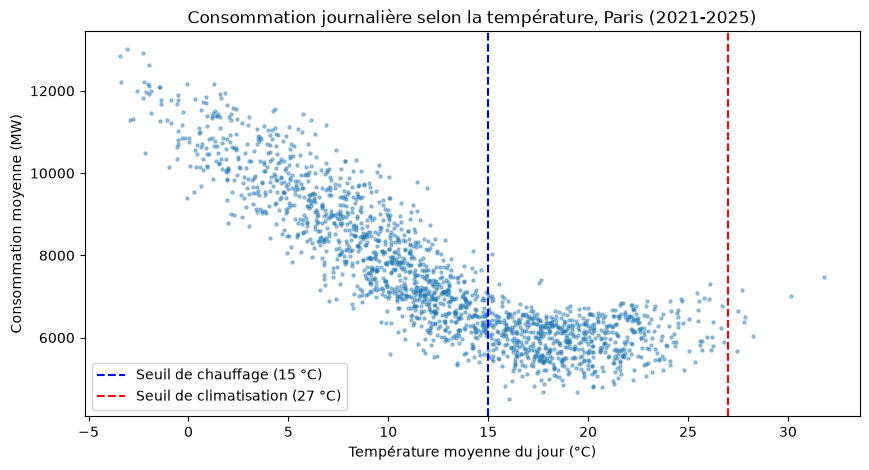

In [15]:
import matplotlib.pyplot as plt
from src.meteo import SEUIL_FROID, SEUIL_CHAUD

ville = "paris"
d = conso_jour[conso_jour["ville"] == ville]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(d["temperature_2m"], d["consommation"], s=5, alpha=0.4)
ax.axvline(SEUIL_FROID, color="blue", linestyle="--", label="Seuil de chauffage (" + str(SEUIL_FROID) + " °C)")
ax.axvline(SEUIL_CHAUD, color="red", linestyle="--", label="Seuil de climatisation (" + str(SEUIL_CHAUD) + " °C)")
ax.set_title("Consommation journalière selon la température, " + ville.capitalize() + " (2021-2025)")
ax.set_xlabel("Température moyenne du jour (°C)")
ax.set_ylabel("Consommation moyenne (MW)")
ax.legend()
plt.show()



In [16]:
def correlation(df):
    """Corrélation entre la température et la consommation d'un sous-tableau."""
    return df["temperature_2m"].corr(df["consommation"])

#Corrélation calculée uniquement sur les jours froids (sous le seuil de chauffage), région par région
jours_froids = conso_jour[conso_jour["temperature_2m"] < SEUIL_FROID]
correl_froid = jours_froids.groupby("ville").apply(correlation).sort_values()
display(correl_froid)

#Nombre de jours au-dessus du seuil de climatisation, par ville
display((conso_jour["temperature_2m"] > SEUIL_CHAUD).groupby(conso_jour["ville"]).sum())


ville
paris        -0.882959
rouen        -0.877842
orleans      -0.874250
bordeaux     -0.868869
toulouse     -0.860610
rennes       -0.858371
lyon         -0.846217
nantes       -0.837996
lille        -0.826669
dijon        -0.825883
marseille    -0.800558
strasbourg   -0.792968
dtype: float64

ville
bordeaux      34
dijon         10
lille          2
lyon          47
marseille     42
nantes        15
orleans        8
paris          8
rennes         8
rouen          2
strasbourg    10
toulouse      70
Name: temperature_2m, dtype: int64

On va maintenant passer à nos 4 hypothèses de production.

Production 1 : La production éolienne augmente avec la vitesse du vent.

Cette hypothèse est assez évidente et relativement peu ambitieuse donc on essaiera avec un scatter d'identifier exactement la relation entre ces deux variables.

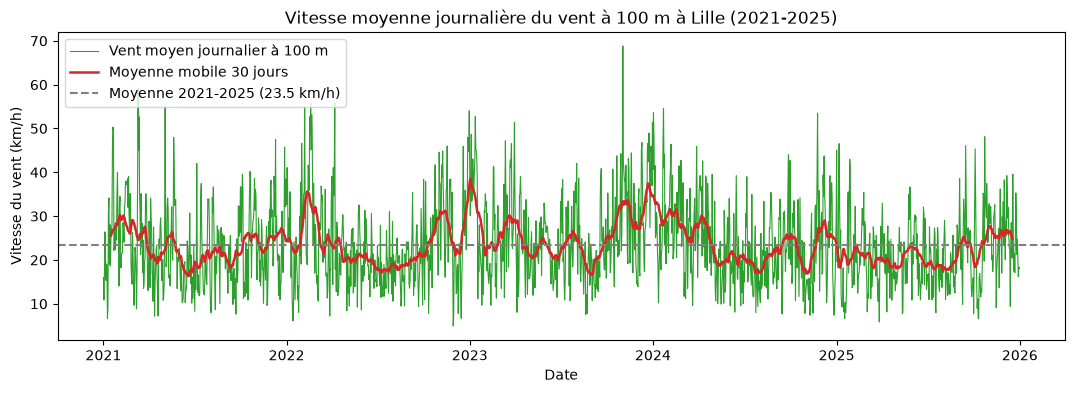

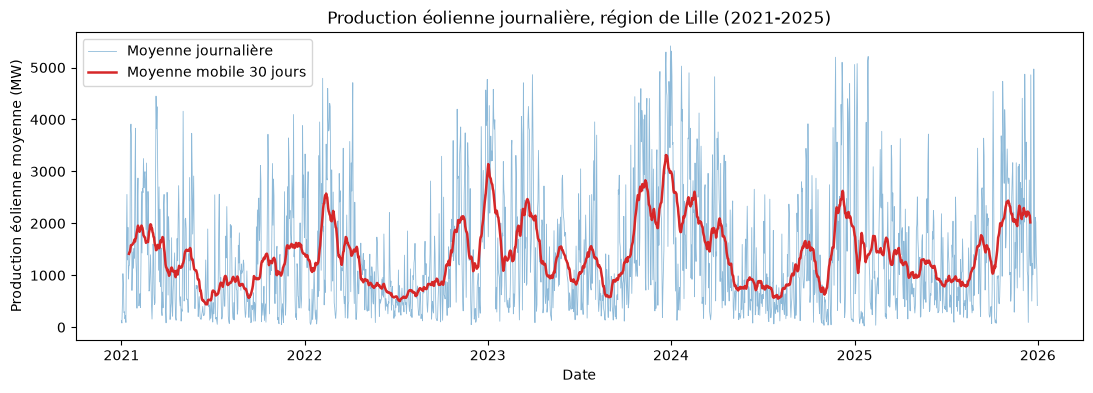

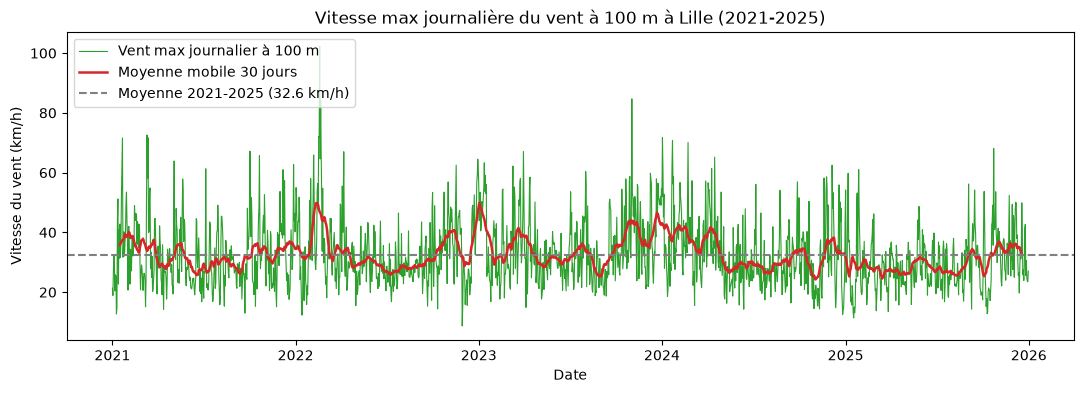

In [ ]:

from src.stats_graph import tracer_graphique_eolien
from src.meteo import tracer_vent_moyen_jour
from src.meteo import tracer_vent_max_jour

ville = "lille" #On a choisit Lille car il  y a une grande production éolien selon le graphique détaillant le mix énérgétique de chaque région
tracer_vent_moyen_jour(meteo, ville)
tracer_graphique_eolien(donnees, ville)
tracer_vent_max_jour(meteo, ville)


En regargant les moyennes mobiles, on observe clairement que les graphs sont très très similaire (pics et chutes au même moment, même forme à peu de chose près)
Cela confirme (sans aucunes surprises) notre hypothèse de causalité entre la production éolien et la vitesse du vent. A noter tout de même que nos données étaient enrgistrer dans les villes respectives et donc potentiellement loin des parcs éoliens (cela ne semble pas avoir trop poser problèmes).
On va étudier l'effet plus en détail pour aller plus loin et être plus rigoureux.

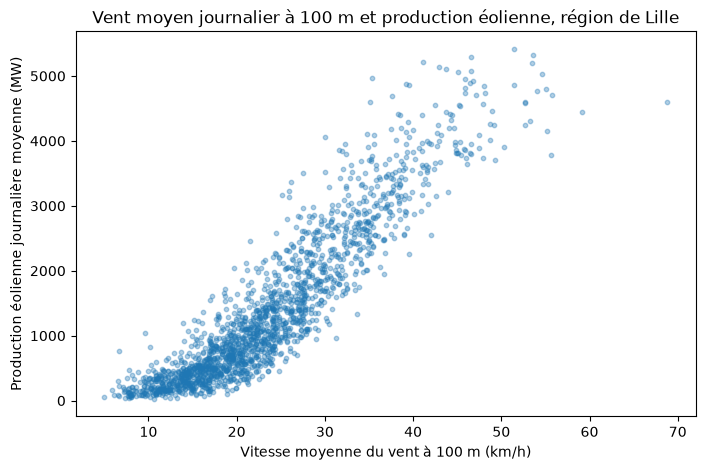

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from src.stats_graph import tracer_scatter_vent_eolien


tracer_scatter_vent_eolien(donnees, "lille")


On n'observe pas vraiment une relation linéaire entre les deux variables, mais plutot une relation y=x**3 avec un début de courbe assez plats puis une envolée.
En recherchant sur internet on confirme que c'est bien la relation entre production éléctrique et vitesse du vent ! 

In [19]:
#Production 2 : La production solaire suit l'ensoleillement : nulle la nuit, maximale vers midi et en été

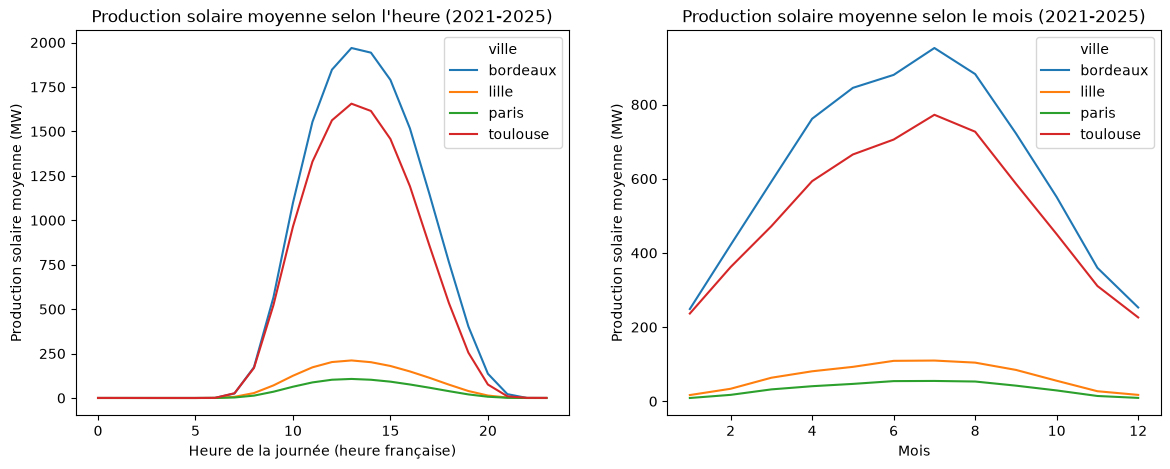

In [20]:
import matplotlib.pyplot as plt

#Hypothèse solaire : on extrait l'heure de la journée et le mois (time est déjà en heure française)
donnees["heure"] = donnees["time"].dt.hour
donnees["mois"] = donnees["time"].dt.month

#On compare deux régions très solaires du Sud et deux régions du Nord
villes = ["toulouse", "bordeaux", "paris", "lille"]
d = donnees[donnees["ville"].isin(villes)]

#Production solaire moyenne pour chaque heure (puis chaque mois), une colonne par ville
profil_heure = d.groupby(["heure", "ville"])["solaire"].mean().unstack()
profil_mois = d.groupby(["mois", "ville"])["solaire"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

profil_heure.plot(ax=axes[0])
axes[0].set_title("Production solaire moyenne selon l'heure (2021-2025)")
axes[0].set_xlabel("Heure de la journée (heure française)")
axes[0].set_ylabel("Production solaire moyenne (MW)")

profil_mois.plot(ax=axes[1])
axes[1].set_title("Production solaire moyenne selon le mois (2021-2025)")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Production solaire moyenne (MW)")

plt.show()


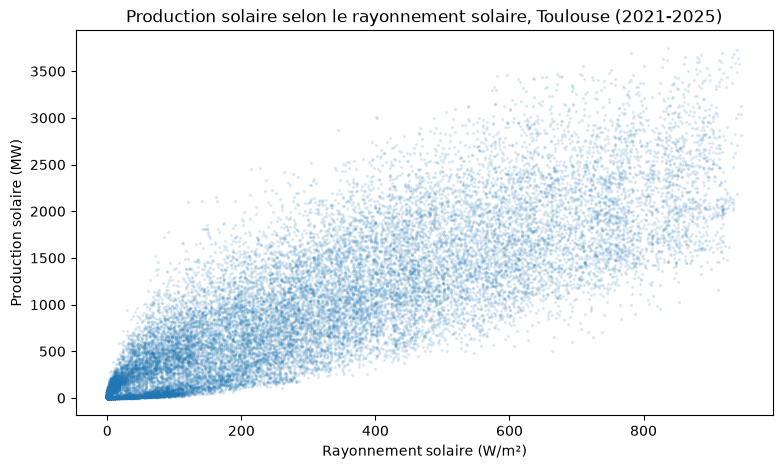

In [21]:
ville = "toulouse"
t = donnees[donnees["ville"] == ville]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t["shortwave_radiation"], t["solaire"], s=2, alpha=0.1)
ax.set_title("Production solaire selon le rayonnement solaire, " + ville.capitalize() + " (2021-2025)")
ax.set_xlabel("Rayonnement solaire (W/m²)")
ax.set_ylabel("Production solaire (MW)")
plt.show()


In [22]:
def correlation_solaire(df):
    """Corrélation entre le rayonnement solaire et la production solaire d'un sous-tableau."""
    return df["shortwave_radiation"].corr(df["solaire"])

correl_solaire = donnees.groupby("ville").apply(correlation_solaire).sort_values()
display(correl_solaire)


ville
dijon         0.830548
rennes        0.831783
strasbourg    0.838301
lille         0.842761
paris         0.849774
orleans       0.857390
nantes        0.859363
rouen         0.874335
lyon          0.877835
toulouse      0.908257
bordeaux      0.914521
marseille     0.921366
dtype: float64

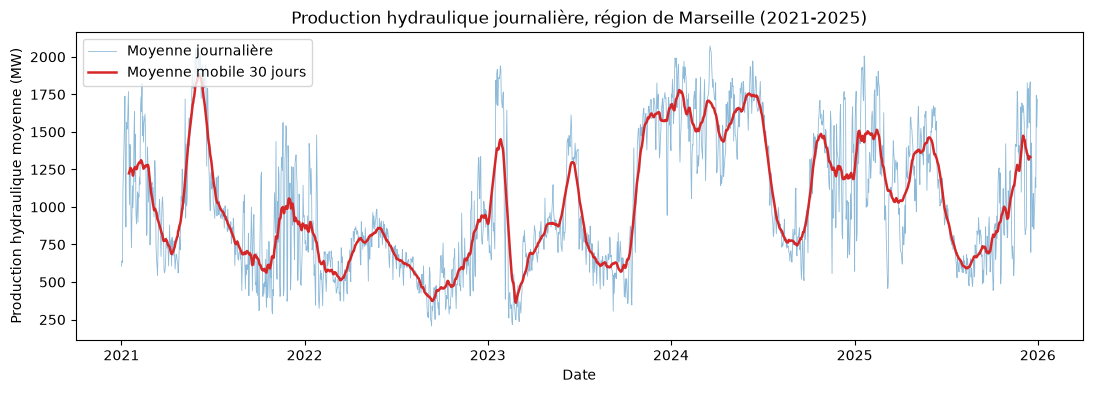

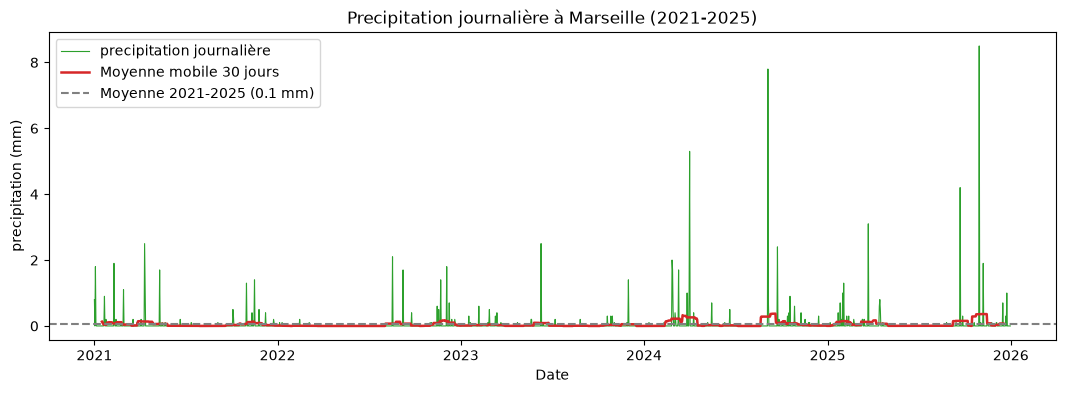

In [ ]:
#Production 3 :La production hydraulique dépend des précipitations, avec un décalage dans le temps.
import importlib
import src.stats_graph
importlib.reload(src.stats_graph)
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="marseille"

tracer_graphique_hydrau(donnees, ville, col_prod="hydraulique", groupe="ville")
tracer_precipitation_jour(meteo, ville)


Si on essaie la même méthode que dans production 1, ce n'est pas très lisible car les valeurs extrêmes écrasent le graphique. Plutôt que supprimer ces outliers on va plutôt travailler en agrégeant par mois.

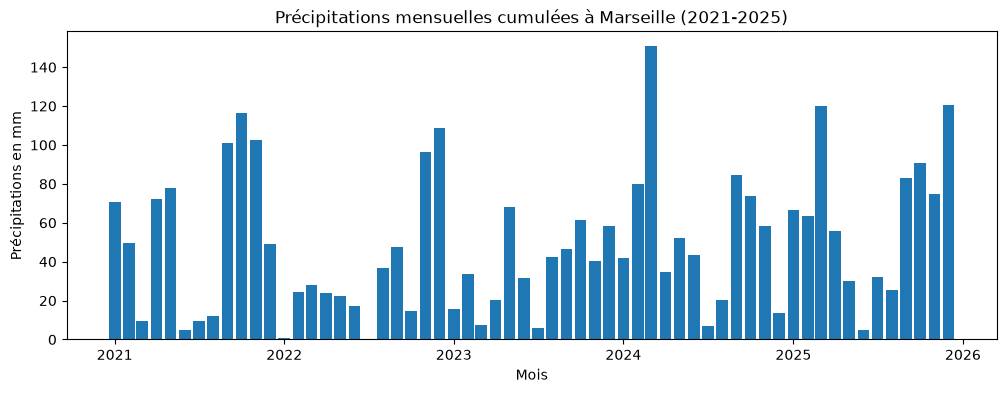

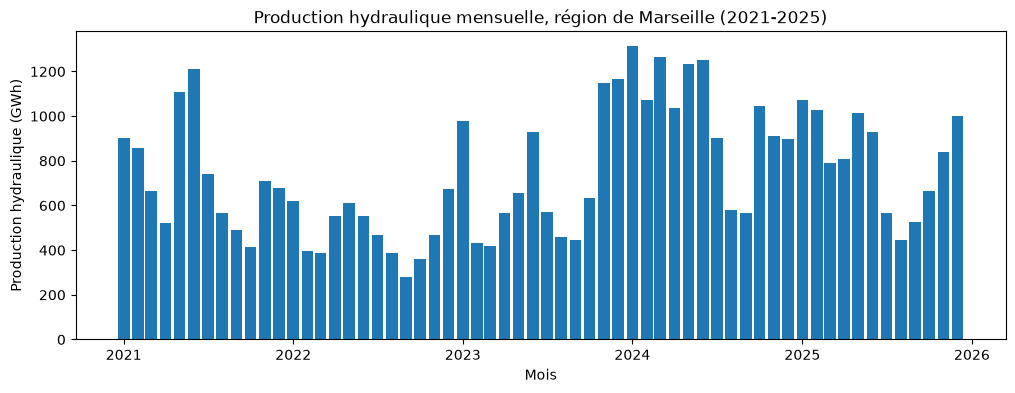

In [29]:
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="marseille"

tracer_cumul_mensuel_precipitation(meteo,ville)
tracer_hydrau_mois(donnees, ville, col_prod="hydraulique")

Ici la conclusion est nettement moins claire que dans production #1 (ce qui est attendu). On va essayer tout de même de vérifier si ce n'est pas simplement du à un décalage comme on en avait fait l'hypothèse.

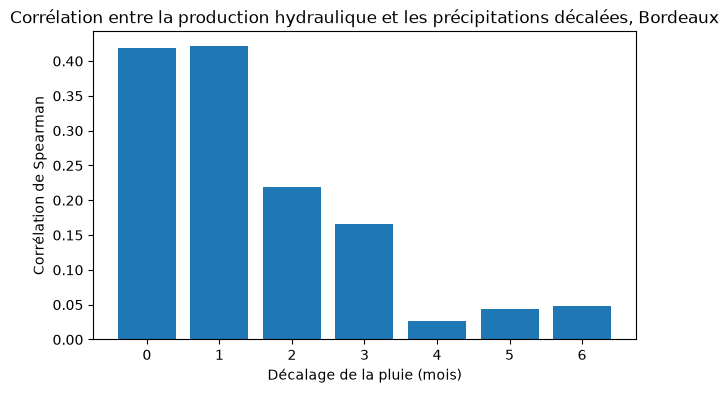

In [31]:
import pandas as pd 
from src.meteo import cumul_mensuel_precipitation
from src.stats_graph import production_mensuelle, corr, tracer_graph_hydrau_pluie, tracer_scatter_pluie_prec


ville = "bordeaux"   # Auvergne-Rhône-Alpes : région hydraulique majeure

pluie =cumul_mensuel_precipitation(meteo,ville)
pluie.index = pluie.index.tz_localize(None)          # même format d'index que la production
prod = production_mensuelle(donnees, ville, "hydraulique")
corr(pluie,prod,ville)


On fait alors l'hypothèse que le décalage de la pluie est de 1 mois. Cependant un coefficient de 0.4 n'est pas très impressionant

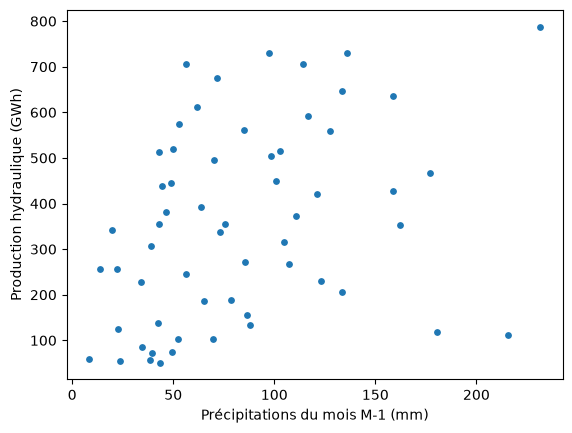

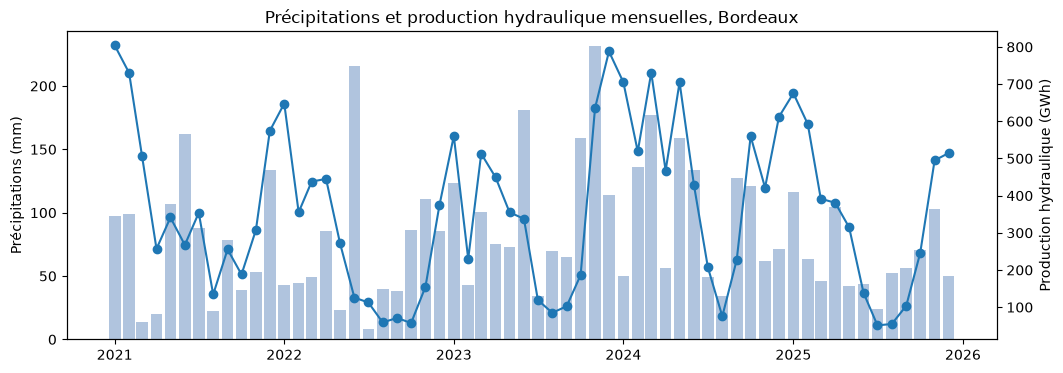

In [ ]:
tracer_scatter_pluie_prec(pluie,prod,ville)
tracer_graph_hydrau_pluie(pluie,prod,ville)

On n'arrive pas vraiment à montrer une corrélation ou encore une causalité. C'est en fait un peu attendu : la production hydraulique dépend de beaucoup plus de facteurs que la simple pluie (notamment de si on décide d'ouvrir ou non les barrages). Il est donc tout à fait normal de ne pas parvenir à de résultats concluant ici.

#4 Production nucléaire

In [26]:
#Hypothèse nucléaire : on ne garde que les régions qui ont des centrales (production moyenne > 0)
nuc_moyen = donnees.groupby("ville")["nucleaire"].mean()
villes_nucleaires = nuc_moyen[nuc_moyen > 0].index.tolist()
print("Régions avec centrales : " + str(villes_nucleaires))

#Échelle du jour : production nucléaire moyenne et température MAXIMALE du jour
#(c'est la chaleur de l'après-midi qui réchauffe les fleuves)
nuc_jour = (donnees[donnees["ville"].isin(villes_nucleaires)]
            .groupby(["ville", "jour"])
            .agg(nucleaire=("nucleaire", "mean"), tmax=("temperature_2m", "max"))
            .reset_index())
nuc_jour["jour"] = pd.to_datetime(nuc_jour["jour"])
nuc_jour["mois"] = nuc_jour["jour"].dt.month
nuc_jour["annee"] = nuc_jour["jour"].dt.year

#On compare uniquement les jours d'été entre eux : les centrales sont souvent en maintenance l'été,
#comparer l'été à l'hiver mélangerait l'effet de la chaleur et celui de la maintenance
ete = nuc_jour[nuc_jour["mois"].isin([6, 7, 8])].copy()
ete["canicule"] = ete["tmax"] >= 30


Régions avec centrales : ['bordeaux', 'lille', 'lyon', 'orleans', 'rouen', 'strasbourg', 'toulouse']


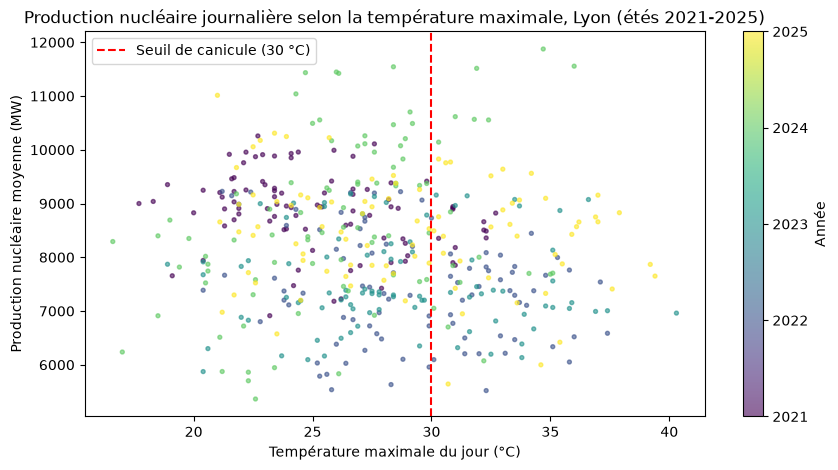

In [27]:
import matplotlib.pyplot as plt

ville = "lyon"
v = ete[ete["ville"] == ville]

fig, ax = plt.subplots(figsize=(10, 5))
nuage = ax.scatter(v["tmax"], v["nucleaire"], s=8, alpha=0.6, c=v["annee"])
fig.colorbar(nuage, label="Année", ticks=[2021, 2022, 2023, 2024, 2025])
ax.axvline(30, color="red", linestyle="--", label="Seuil de canicule (30 °C)")
ax.set_title("Production nucléaire journalière selon la température maximale, " + ville.capitalize() + " (étés 2021-2025)")
ax.set_xlabel("Température maximale du jour (°C)")
ax.set_ylabel("Production nucléaire moyenne (MW)")
ax.legend()
plt.show()


In [28]:
def ecart_canicule(df):
    """Écart (en %) de production nucléaire moyenne entre jours de canicule et autres jours d'été, par ville."""
    moyennes = df.groupby(["ville", "canicule"])["nucleaire"].mean().unstack()
    return ((moyennes[True] / moyennes[False] - 1) * 100).round(1)

comparaison = pd.DataFrame({
    "jours_canicule": ete.groupby("ville")["canicule"].sum(),
    "ecart_toutes_annees_%": ecart_canicule(ete),
    "ecart_sans_2022_%": ecart_canicule(ete[ete["annee"] != 2022]),
})
display(comparaison)


,jours_canicule,ecart_toutes_annees_%,ecart_sans_2022_%
ville,,,
bordeaux,110,-9.3,1.7
lille,21,-8.8,-5.5
lyon,137,-4.7,-3.1
orleans,52,1.2,0.9
rouen,25,-11.3,10.0
strasbourg,70,-15.3,-3.7
toulouse,164,-12.1,-15.1


Conclusions